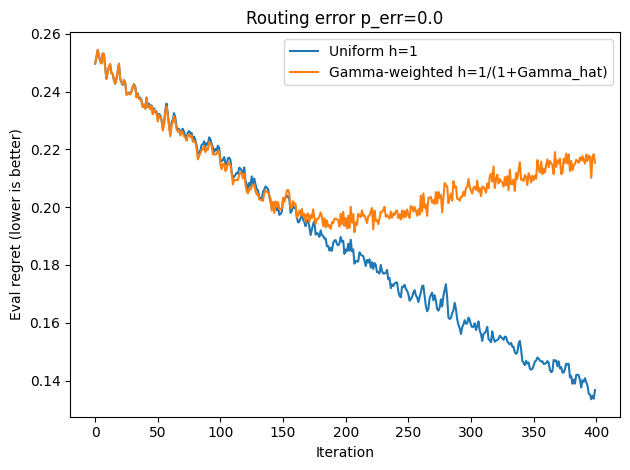

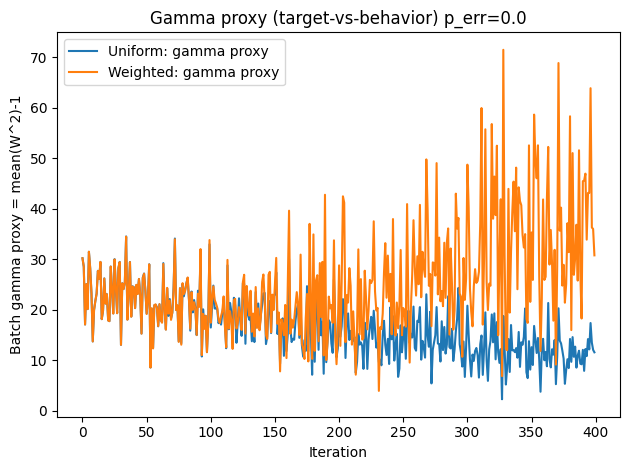

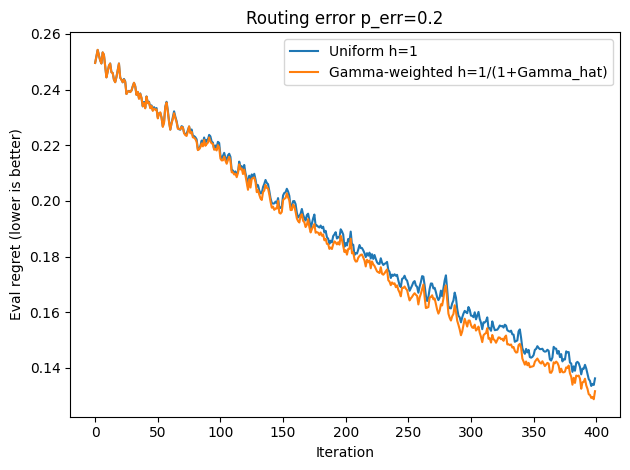

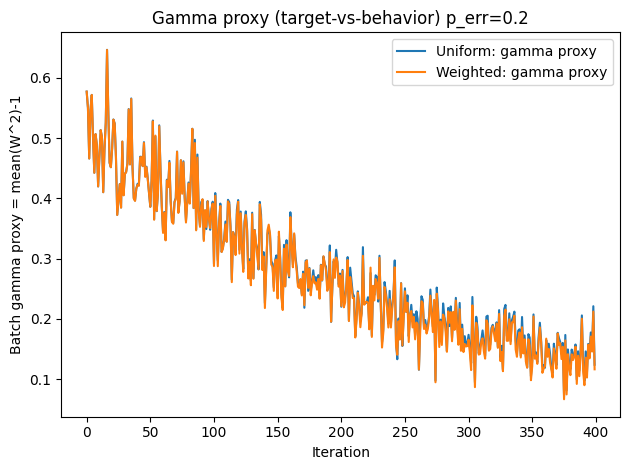

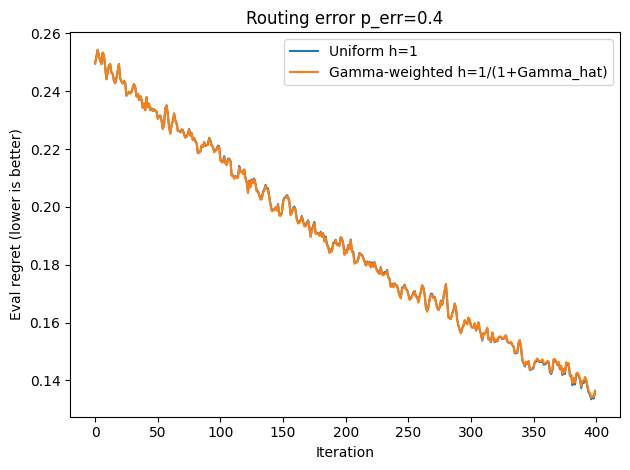

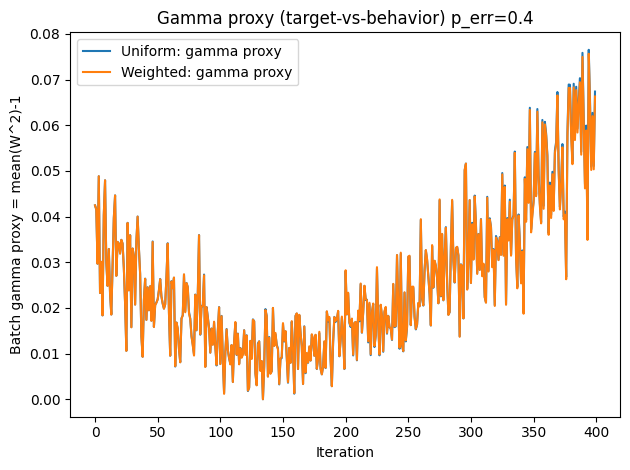

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

class ConditionedPolicy:
    """
    pi_theta(a=0|w) = sigmoid(theta0 + theta1*(w-0.5)), a in {0,1}
    """
    def __init__(self, theta=None):
        self.theta = np.zeros(2) if theta is None else np.array(theta, dtype=float)

    def p0(self, w):
        x = np.array([1.0, w - 0.5])
        return sigmoid(self.theta @ x)

    def prob(self, a, w):
        p0 = self.p0(w)
        return p0 if a == 0 else (1.0 - p0)

    def grad_log_prob(self, a, w):
        # grad wrt theta of log pi(a|w)
        x = np.array([1.0, w - 0.5])
        p0 = self.p0(w)
        if a == 0:
            return (1.0 - p0) * x
        else:
            return (-p0) * x

def oracle_action(w):
    return 0 if w > 0.5 else 1

def sample_reward_vec(a, sigma_r, rng):
    # r in R^2
    if a == 0:
        mean = np.array([1.0, 0.0])
    else:
        mean = np.array([0.0, 1.0])
    return mean + rng.normal(scale=sigma_r, size=2)

class EnsembleBehavior:
    """
    Two experts: expert0 always a=0, expert1 always a=1.
    Routing uses oracle threshold w>0.5, but flips with prob p_err.
    Then apply epsilon exploration floor: with prob eps choose uniform action.
    """
    def __init__(self, p_err=0.2, eps=0.02, rng=None):
        self.p_err = float(p_err)
        self.eps = float(eps)
        self.rng = np.random.default_rng() if rng is None else rng

    def mu_probs(self, w):
        # returns mu(a=0|w), mu(a=1|w)
        a_star = oracle_action(w)
        # intended expert action is a_star, but routing flips with p_err
        p_choose_star = 1.0 - self.p_err
        p_choose_wrong = self.p_err
        # before eps exploration: prob(action=a_star)=p_choose_star, else p_choose_wrong
        p0_noeps = p_choose_star if a_star == 0 else p_choose_wrong
        p1_noeps = 1.0 - p0_noeps
        # eps mixing with uniform
        p0 = (1.0 - self.eps) * p0_noeps + self.eps * 0.5
        p1 = (1.0 - self.eps) * p1_noeps + self.eps * 0.5
        return p0, p1

    def sample_action(self, w):
        p0, p1 = self.mu_probs(w)
        a = 0 if self.rng.random() < p0 else 1
        return a, (p0, p1)

def evaluate_policy(policy, sigma_r, n_eval=20000, seed=0):
    rng = np.random.default_rng(seed)
    regrets = []
    for _ in range(n_eval):
        w = rng.random()
        # sample action from target policy (on-policy eval)
        p0 = policy.p0(w)
        a = 0 if rng.random() < p0 else 1
        r = sample_reward_vec(a, sigma_r, rng)
        y = w * r[0] + (1.0 - w) * r[1]
        # oracle value (in expectation, ignoring noise) is max(w, 1-w)
        q_star = max(w, 1.0 - w)
        regrets.append(q_star - y)
    return float(np.mean(regrets))

def run(seed=0,
        p_err=0.35,
        eps=0.02,
        sigma_r=0.1,
        iters=400,
        batch_size=512,
        lr=0.2,
        n_bins=20,
        use_gamma_weight=True):
    rng = np.random.default_rng(seed)
    behavior = EnsembleBehavior(p_err=p_err, eps=eps, rng=rng)
    policy = ConditionedPolicy(theta=[0.0, 0.0])

    # bin-based observable conflict estimate for ORACLE policy vs behavior
    # We maintain per-bin running mean of W_star^2 where W_star = 1{a=a*}/mu(a*|w).
    bin_counts = np.zeros(n_bins, dtype=int)
    bin_sum_w2 = np.zeros(n_bins, dtype=float)

    def bin_id(w):
        b = int(np.floor(w * n_bins))
        return min(max(b, 0), n_bins - 1)

    regrets = []
    gammas = []
    grad_norms = []

    for t in range(iters):
        # compute predictable weights h(w) from past gamma estimates (per bin)
        # gamma_hat_bin = mean(W_star^2)-1; g_hat_bin = 1/(1+gamma_hat_bin)
        g_hat_bin = np.ones(n_bins, dtype=float)
        for b in range(n_bins):
            if bin_counts[b] > 50:  # wait for enough samples
                m = bin_sum_w2[b] / bin_counts[b]
                gamma_hat = max(m - 1.0, 0.0)
                g_hat_bin[b] = 1.0 / (1.0 + gamma_hat)
            else:
                g_hat_bin[b] = 1.0

        # collect a batch from behavior
        ws = rng.random(batch_size)
        actions = np.zeros(batch_size, dtype=int)
        mu_ps = np.zeros((batch_size, 2), dtype=float)
        ys = np.zeros(batch_size, dtype=float)

        for i in range(batch_size):
            w = float(ws[i])
            a, (p0, p1) = behavior.sample_action(w)
            actions[i] = a
            mu_ps[i, 0] = p0
            mu_ps[i, 1] = p1
            r = sample_reward_vec(a, sigma_r, rng)
            ys[i] = w * r[0] + (1.0 - w) * r[1]

            # update observable conflict stats for oracle policy (uses logged mu + known a*(w))
            b = bin_id(w)
            a_star = oracle_action(w)
            mu_astar = mu_ps[i, a_star]
            w_star = (1.0 / mu_astar) if (a == a_star) else 0.0
            bin_counts[b] += 1
            bin_sum_w2[b] += w_star * w_star

        # compute per-sample h_i (predictable via bin lookup; depends on w only)
        if use_gamma_weight:
            hs = np.zeros(batch_size, dtype=float)
            for i in range(batch_size):
                w = float(ws[i])
                mu0, mu1 = mu_ps[i,0], mu_ps[i,1]         # behavior probs are logged
                pi0 = policy.p0(w)
                pi1 = 1.0 - pi0
                m2 = (pi0*pi0)/(mu0 + 1e-12) + (pi1*pi1)/(mu1 + 1e-12)   # E[W^2 | w]
                hs[i] = 1.0 / (m2 + 1e-12)   # = 1/(1+Gamma_theta(w))
        else:
            hs = np.ones(batch_size, dtype=float)


        # IPS policy gradient on weighted empirical objective
        # grad = (1/sum h) sum_i h_i * y_i * (pi_theta(a_i|w_i)/mu(a_i|w_i)) * grad log pi_theta(a_i|w_i)
        grad = np.zeros_like(policy.theta)
        denom = float(np.sum(hs)) + 1e-12
        w2_batch = []

        for i in range(batch_size):
            w = float(ws[i])
            a = int(actions[i])
            mu_a = float(mu_ps[i, a])
            pi_a = float(policy.prob(a, w))
            W = pi_a / (mu_a + 1e-12)
            grad += hs[i] * ys[i] * W * policy.grad_log_prob(a, w)
            w2_batch.append(W * W)

        grad /= denom
        # policy.theta += lr * grad
        gamma_hat = max(np.mean(w2_batch) - 1.0, 0.0)
        h_t = 1.0 / (1.0 + min(gamma_hat, Gmax))   # scalar

        # 你的原 grad（不带 sample-level hs）
        policy.theta += lr * h_t * grad


        # logging: observable gamma proxy for current target policy on this batch (not oracle)
        gamma_batch = float(np.mean(w2_batch) - 1.0)
        gammas.append(max(gamma_batch, 0.0))
        grad_norms.append(float(np.linalg.norm(grad)))

        # evaluation regret (on-policy under current policy)
        regrets.append(evaluate_policy(policy, sigma_r, n_eval=6000, seed=seed + 999 + t))

    return {
        "regret": np.array(regrets),
        "gamma_proxy": np.array(gammas),
        "grad_norm": np.array(grad_norms),
    }

if __name__ == "__main__":
    # Sweep routing error to show conflict -> sample complexity
    seeds = [0, 1, 2]
    p_err_list = [0.0, 0.2, 0.4]

    for p_err in p_err_list:
        out_u = [run(seed=s, p_err=p_err, use_gamma_weight=False) for s in seeds]
        out_w = [run(seed=s, p_err=p_err, use_gamma_weight=True) for s in seeds]

        def mean_curve(key, outs):
            return np.mean([o[key] for o in outs], axis=0)

        reg_u = mean_curve("regret", out_u)
        reg_w = mean_curve("regret", out_w)
        gam_u = mean_curve("gamma_proxy", out_u)
        gam_w = mean_curve("gamma_proxy", out_w)

        plt.figure()
        plt.plot(reg_u, label="Uniform h=1")
        plt.plot(reg_w, label="Gamma-weighted h=1/(1+Gamma_hat)")
        plt.xlabel("Iteration")
        plt.ylabel("Eval regret (lower is better)")
        plt.title(f"Routing error p_err={p_err}")
        plt.legend()
        plt.tight_layout()
        plt.show()

        plt.figure()
        plt.plot(gam_u, label="Uniform: gamma proxy")
        plt.plot(gam_w, label="Weighted: gamma proxy")
        plt.xlabel("Iteration")
        plt.ylabel("Batch gamma proxy = mean(W^2)-1")
        plt.title(f"Gamma proxy (target-vs-behavior) p_err={p_err}")
        plt.legend()
        plt.tight_layout()
        plt.show()


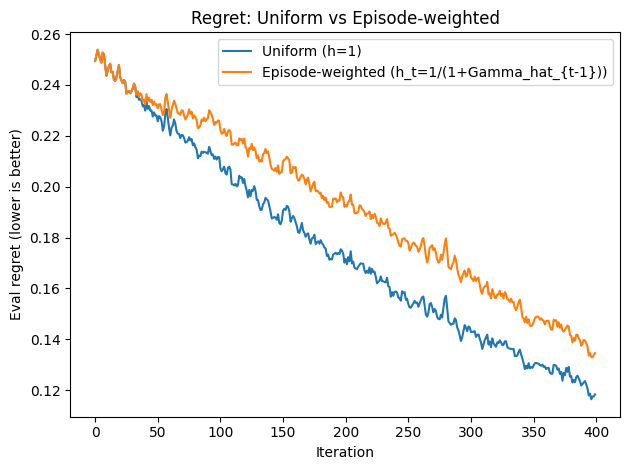

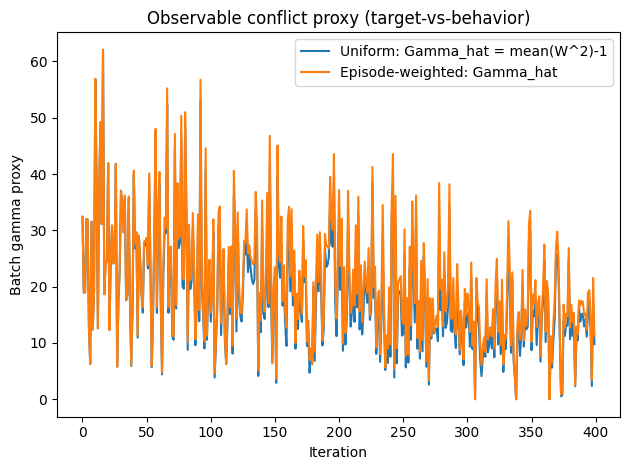

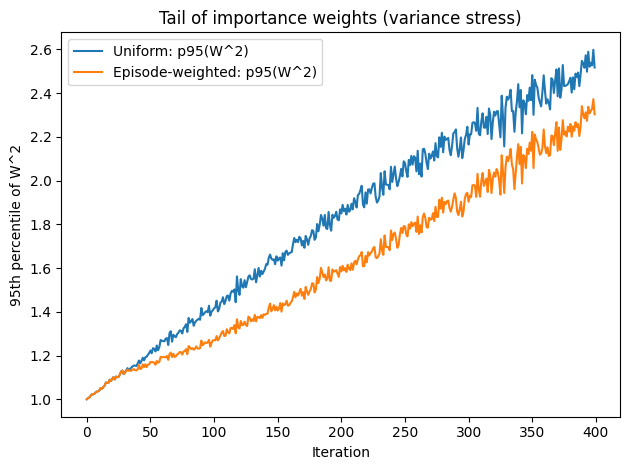

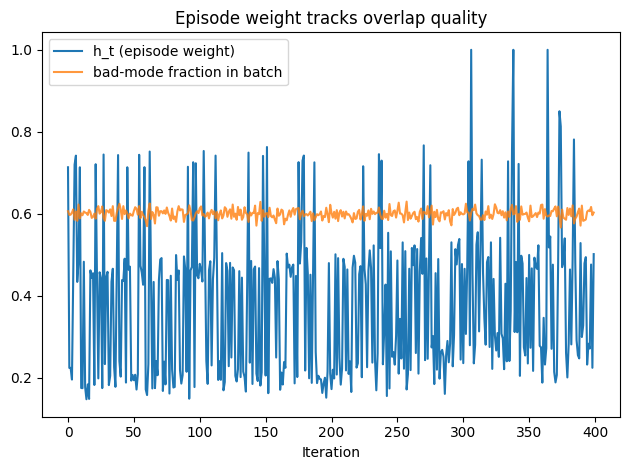

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Utilities
# -------------------------
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def oracle_action(w: float) -> int:
    return 0 if w > 0.5 else 1

def sample_reward_vec(a: int, sigma_r: float, rng: np.random.Generator) -> np.ndarray:
    # Vector reward r in R^2
    if a == 0:
        mean = np.array([1.0, 0.0])
    else:
        mean = np.array([0.0, 1.0])
    return mean + rng.normal(scale=sigma_r, size=2)

# -------------------------
# Policy: logistic conditioned on w
# -------------------------
class ConditionedPolicy:
    """
    pi_theta(a=0|w) = sigmoid(theta0 + theta1*(w-0.5))
    """
    def __init__(self, theta=None):
        self.theta = np.zeros(2) if theta is None else np.array(theta, dtype=float)

    def p0(self, w: float) -> float:
        x = np.array([1.0, w - 0.5])
        return sigmoid(self.theta @ x)

    def prob(self, a: int, w: float) -> float:
        p0 = self.p0(w)
        return p0 if a == 0 else (1.0 - p0)

    def grad_log_prob(self, a: int, w: float) -> np.ndarray:
        # grad wrt theta of log pi(a|w)
        x = np.array([1.0, w - 0.5])
        p0 = self.p0(w)
        # d/dtheta log sigma = (1 - sigma) x ; d/dtheta log (1-sigma) = -sigma x
        if a == 0:
            return (1.0 - p0) * x
        else:
            return (-p0) * x

# -------------------------
# Behavior: ensemble routing with optional two-mode switching
# -------------------------
class TwoModeEnsembleBehavior:
    """
    Each episode picks a "mode" k ~ Categorical(p_mode).
    Mode k has its own (p_err, eps) describing:
      - two experts: expert0 always a=0, expert1 always a=1
      - routing uses oracle threshold but flips with prob p_err
      - epsilon exploration mixes with uniform actions
    """
    def __init__(self, modes, p_mode, rng=None):
        """
        modes: list of dicts, each has {"p_err": float, "eps": float}
        p_mode: list/array of probabilities summing to 1
        """
        self.modes = modes
        self.p_mode = np.array(p_mode, dtype=float) / np.sum(p_mode)
        self.rng = np.random.default_rng() if rng is None else rng

    def mu_probs_given_mode(self, w: float, p_err: float, eps: float):
        a_star = oracle_action(w)
        # before eps, prob(action=a_star)=1-p_err, prob(wrong)=p_err
        p0_noeps = (1.0 - p_err) if a_star == 0 else p_err
        p1_noeps = 1.0 - p0_noeps
        # eps mixing with uniform
        p0 = (1.0 - eps) * p0_noeps + eps * 0.5
        p1 = (1.0 - eps) * p1_noeps + eps * 0.5
        return p0, p1

    def sample_action(self, w: float):
        # pick mode
        k = int(self.rng.choice(len(self.modes), p=self.p_mode))
        p_err = float(self.modes[k]["p_err"])
        eps = float(self.modes[k]["eps"])
        p0, p1 = self.mu_probs_given_mode(w, p_err, eps)
        a = 0 if self.rng.random() < p0 else 1
        return a, (p0, p1), k

# -------------------------
# Evaluation: on-policy regret under uniform w
# -------------------------
def evaluate_policy(policy: ConditionedPolicy, sigma_r: float, n_eval=20000, seed=0) -> float:
    rng = np.random.default_rng(seed)
    regrets = []
    for _ in range(n_eval):
        w = float(rng.random())
        p0 = policy.p0(w)
        a = 0 if rng.random() < p0 else 1
        r = sample_reward_vec(a, sigma_r, rng)
        y = w * r[0] + (1.0 - w) * r[1]
        q_star = max(w, 1.0 - w)  # oracle expected scalarized reward (noise-free)
        regrets.append(q_star - y)
    return float(np.mean(regrets))

# -------------------------
# Training loop
# -------------------------
def run(seed=0,
        iters=400,
        batch_size=512,
        lr=0.25,
        sigma_r=0.1,
        # Two behavior modes: "bad overlap" vs "good overlap"
        modes=None,
        p_mode=None,
        # episode-level gamma weighting
        use_episode_weight=True,
        Gmax=50.0,
        W_clip=None):
    rng = np.random.default_rng(seed)

    h_t = 1.0
    h_bar = 1.0          # running mean of h_t
    beta = 0.01          # EMA rate
    h_min = 0.05         # prevent killing all learning
    warmup = 30          # first N iters no weighting


    if modes is None:
        # Bad: almost deterministic (eps small, routing correct) -> overlap bad for off-policy learning if pi explores wrong action
        # Good: very mixed -> overlap good
        modes = [
            {"p_err": 0.0, "eps": 0.02},  # bad mode
            {"p_err": 0.5, "eps": 0.30},  # good mode
        ]
    if p_mode is None:
        p_mode = [0.5, 0.5]

    behavior = TwoModeEnsembleBehavior(modes=modes, p_mode=p_mode, rng=rng)
    policy = ConditionedPolicy(theta=[0.0, 0.0])

    # episode-level predictable weight h_t (initialize to 1)
    h_t = 1.0

    # logs
    eval_regret = []
    gamma_hat_list = []
    h_list = []
    mean_w2_list = []
    p95_w2_list = []
    mode_frac_bad = []  # fraction of samples from mode 0 in this batch

    for t in range(iters):
        # collect batch under behavior
        ws = rng.random(batch_size)
        actions = np.zeros(batch_size, dtype=int)
        mu_ps = np.zeros((batch_size, 2), dtype=float)
        ys = np.zeros(batch_size, dtype=float)
        modes_used = np.zeros(batch_size, dtype=int)

        for i in range(batch_size):
            w = float(ws[i])
            a, (p0, p1), k = behavior.sample_action(w)
            actions[i] = a
            mu_ps[i, 0] = p0
            mu_ps[i, 1] = p1
            modes_used[i] = k
            r = sample_reward_vec(a, sigma_r, rng)
            ys[i] = w * r[0] + (1.0 - w) * r[1]

        # compute IPS-PG gradient on this batch (unweighted within batch)
        grad = np.zeros_like(policy.theta)
        w2_batch = np.zeros(batch_size, dtype=float)

        for i in range(batch_size):
            w = float(ws[i])
            a = int(actions[i])
            mu_a = float(mu_ps[i, a])
            pi_a = float(policy.prob(a, w))
            W = pi_a / (mu_a + 1e-12)
            if W_clip is not None:
                W = min(W, float(W_clip))
            w2_batch[i] = W * W
            grad += ys[i] * W * policy.grad_log_prob(a, w)

        grad /= float(batch_size)

        # --- update: episode-level scaling ---
        # init before loop:
        # h_t=1.0; h_bar=1.0; beta=0.01; h_min=0.05; warmup=30

        # inside loop, before update:
        if use_episode_weight and t >= warmup:
            h_eff = max(h_min, h_t / (h_bar + 1e-12))
        else:
            h_eff = 1.0

        policy.theta += lr * h_eff * grad

        # after computing gamma_hat:
        mean_w2 = float(np.mean(w2_batch))
        gamma_hat = max(mean_w2 - 1.0, 0.0)
        if use_episode_weight:
            # option A: aggressive
            # h_t = 1.0 / (1.0 + min(gamma_hat, Gmax))
            # option B: safer (recommended)
            h_t = 1.0 / np.sqrt(1.0 + min(gamma_hat, Gmax))
        else:
            h_t = 1.0

        h_bar = (1.0 - beta) * h_bar + beta * h_t


        # logging
        mean_w2_list.append(mean_w2)
        p95_w2_list.append(float(np.percentile(w2_batch, 95)))
        gamma_hat_list.append(gamma_hat)
        h_list.append(h_t)
        mode_frac_bad.append(float(np.mean(modes_used == 0)))

        eval_regret.append(
            evaluate_policy(policy, sigma_r, n_eval=6000, seed=seed + 999 + t)
        )

    return {
        "eval_regret": np.array(eval_regret),
        "gamma_hat": np.array(gamma_hat_list),
        "h": np.array(h_list),
        "mean_w2": np.array(mean_w2_list),
        "p95_w2": np.array(p95_w2_list),
        "mode_frac_bad": np.array(mode_frac_bad),
    }

# -------------------------
# Main: compare uniform vs episode-weighted
# -------------------------
if __name__ == "__main__":
    seeds = [0, 1, 2]

    # You can tune these to make the gap clearer:
    # - Increase "bad mode" frequency to stress the learner
    modes = [
        {"p_err": 0.0, "eps": 0.01},  # bad overlap
        {"p_err": 0.5, "eps": 0.30},  # good overlap
    ]
    p_mode = [0.6, 0.4]  # 60% bad mode, 40% good mode

    outs_uniform = [run(seed=s, use_episode_weight=False, lr=0.25, modes=modes, p_mode=p_mode) for s in seeds]
    outs_weighted = [run(seed=s, use_episode_weight=True,  lr=0.25, modes=modes, p_mode=p_mode) for s in seeds]

    def mean_curve(key, outs):
        return np.mean([o[key] for o in outs], axis=0)

    reg_u = mean_curve("eval_regret", outs_uniform)
    reg_w = mean_curve("eval_regret", outs_weighted)
    gam_u = mean_curve("gamma_hat", outs_uniform)
    gam_w = mean_curve("gamma_hat", outs_weighted)
    h_w = mean_curve("h", outs_weighted)
    p95_u = mean_curve("p95_w2", outs_uniform)
    p95_w = mean_curve("p95_w2", outs_weighted)
    frac_bad = mean_curve("mode_frac_bad", outs_weighted)

    plt.figure()
    plt.plot(reg_u, label="Uniform (h=1)")
    plt.plot(reg_w, label="Episode-weighted (h_t=1/(1+Gamma_hat_{t-1}))")
    plt.xlabel("Iteration")
    plt.ylabel("Eval regret (lower is better)")
    plt.title("Regret: Uniform vs Episode-weighted")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure()
    plt.plot(gam_u, label="Uniform: Gamma_hat = mean(W^2)-1")
    plt.plot(gam_w, label="Episode-weighted: Gamma_hat")
    plt.xlabel("Iteration")
    plt.ylabel("Batch gamma proxy")
    plt.title("Observable conflict proxy (target-vs-behavior)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure()
    plt.plot(p95_u, label="Uniform: p95(W^2)")
    plt.plot(p95_w, label="Episode-weighted: p95(W^2)")
    plt.xlabel("Iteration")
    plt.ylabel("95th percentile of W^2")
    plt.title("Tail of importance weights (variance stress)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure()
    plt.plot(h_w, label="h_t (episode weight)")
    plt.plot(frac_bad, label="bad-mode fraction in batch", alpha=0.8)
    plt.xlabel("Iteration")
    plt.title("Episode weight tracks overlap quality")
    plt.legend()
    plt.tight_layout()
    plt.show()


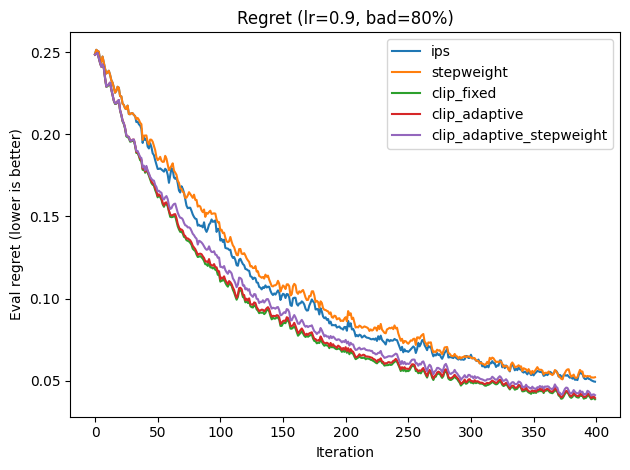

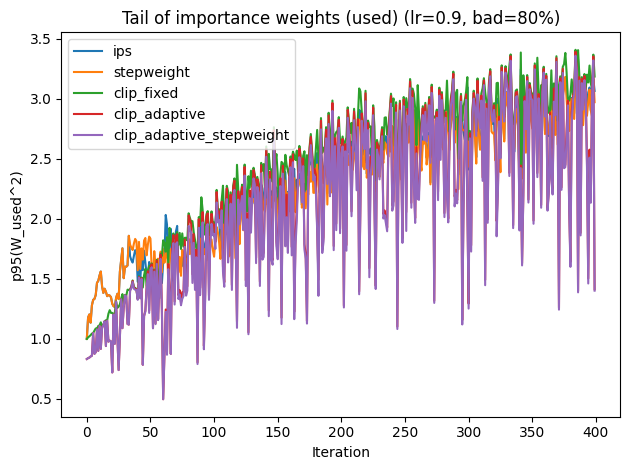

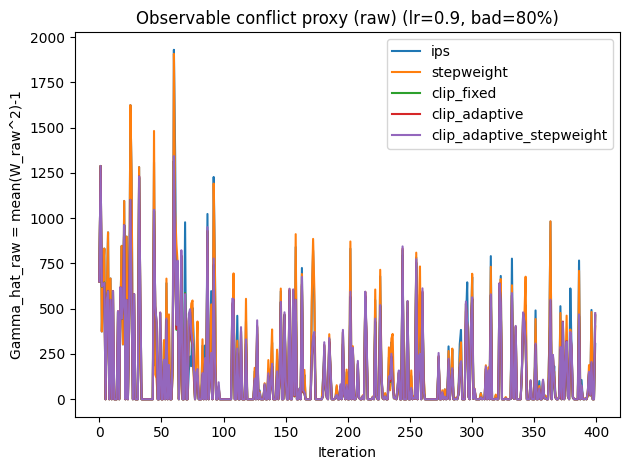

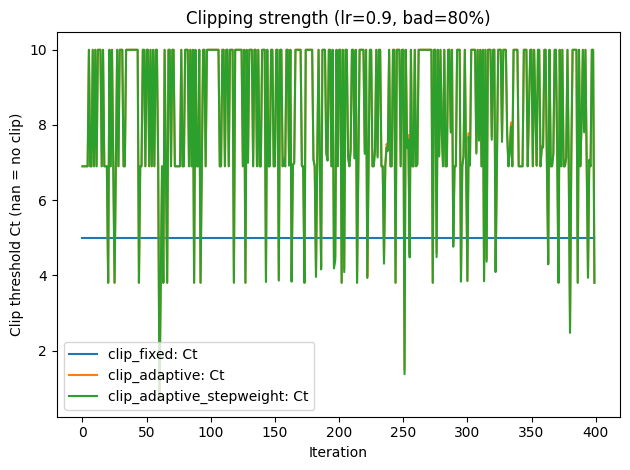

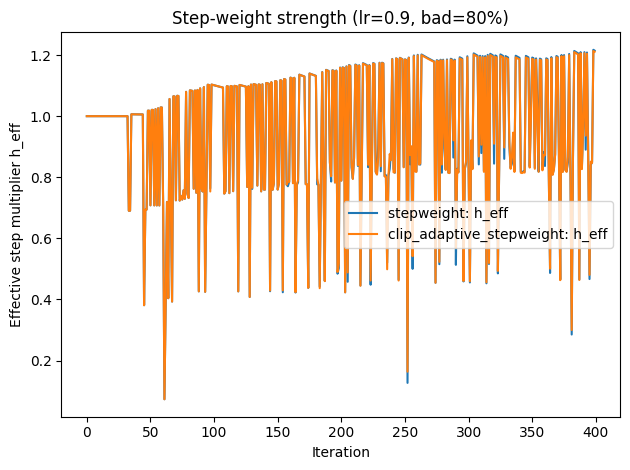

In [5]:
# ============================================================
# Toy MORL bandit (H=1 RL) + IPS Policy Gradient
# Methods controlled by a Python variable `method` (Jupyter-friendly)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Utilities
# -------------------------
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def oracle_action(w: float) -> int:
    return 0 if w > 0.5 else 1

def sample_reward_vec(a: int, sigma_r: float, rng: np.random.Generator) -> np.ndarray:
    # Vector reward r in R^2
    if a == 0:
        mean = np.array([1.0, 0.0])
    else:
        mean = np.array([0.0, 1.0])
    return mean + rng.normal(scale=sigma_r, size=2)

def scalarize_reward(w: float, r_vec: np.ndarray) -> float:
    return w * r_vec[0] + (1.0 - w) * r_vec[1]

# -------------------------
# Policy: logistic conditioned on preference/context w
# -------------------------
class ConditionedPolicy:
    """
    pi_theta(a=0|w) = sigmoid(theta0 + theta1*(w-0.5)), a in {0,1}
    """
    def __init__(self, theta=None):
        self.theta = np.zeros(2) if theta is None else np.array(theta, dtype=float)

    def p0(self, w: float) -> float:
        x = np.array([1.0, w - 0.5])
        return sigmoid(self.theta @ x)

    def prob(self, a: int, w: float) -> float:
        p0 = self.p0(w)
        return p0 if a == 0 else (1.0 - p0)

    def grad_log_prob(self, a: int, w: float) -> np.ndarray:
        x = np.array([1.0, w - 0.5])
        p0 = self.p0(w)
        if a == 0:
            return (1.0 - p0) * x
        else:
            return (-p0) * x

# -------------------------
# Behavior policy: two-expert ensemble + routing error + eps exploration,
# optionally switching between "modes" each episode (good vs bad overlap)
# -------------------------
class TwoModeEnsembleBehavior:
    """
    Each episode picks a mode k ~ Categorical(p_mode).
    Mode k has (p_err, eps):
      - oracle routing (threshold at w=0.5), flipped with prob p_err
      - epsilon exploration mixes with uniform action
    """
    def __init__(self, modes, p_mode, rng=None):
        self.modes = list(modes)
        self.p_mode = np.array(p_mode, dtype=float)
        self.p_mode = self.p_mode / np.sum(self.p_mode)
        self.rng = np.random.default_rng() if rng is None else rng

    def mu_probs_given_mode(self, w: float, p_err: float, eps: float):
        a_star = oracle_action(w)
        # before eps: choose a_star w.p. 1-p_err, choose wrong w.p. p_err
        p0_noeps = (1.0 - p_err) if a_star == 0 else p_err
        p1_noeps = 1.0 - p0_noeps
        # eps mix with uniform
        p0 = (1.0 - eps) * p0_noeps + eps * 0.5
        p1 = (1.0 - eps) * p1_noeps + eps * 0.5
        return p0, p1

    def sample_action(self, w: float):
        k = int(self.rng.choice(len(self.modes), p=self.p_mode))
        p_err = float(self.modes[k]["p_err"])
        eps = float(self.modes[k]["eps"])
        p0, p1 = self.mu_probs_given_mode(w, p_err, eps)
        a = 0 if self.rng.random() < p0 else 1
        return a, (p0, p1), k

# -------------------------
# Evaluation (on-policy regret under uniform w)
# -------------------------
def evaluate_policy(policy: ConditionedPolicy, sigma_r: float, n_eval=20000, seed=0) -> float:
    rng = np.random.default_rng(seed)
    regrets = []
    for _ in range(n_eval):
        w = float(rng.random())
        a = 0 if rng.random() < policy.p0(w) else 1
        r = sample_reward_vec(a, sigma_r, rng)
        y = scalarize_reward(w, r)
        q_star = max(w, 1.0 - w)  # oracle expected scalarized reward (noise-free)
        regrets.append(q_star - y)
    return float(np.mean(regrets))

# ============================================================
# Core training loop with selectable method
# ============================================================
def run(method: str,
        seed: int = 0,
        iters: int = 400,
        batch_size: int = 512,
        lr: float = 0.8,
        sigma_r: float = 0.1,
        # behavior modes: make "bad" overlap quite extreme to stress IPS
        modes=None,
        p_mode=None,
        # clipping params
        C_fixed: float = 5.0,
        C0: float = 10.0,
        Gmax: float = 200.0,
        # step-weight params (episode-level)
        weight_pow: float = 0.5,     # h = (1+Gamma)^(-weight_pow); 0.5 is sqrt
        warmup: int = 30,            # first warmup iterations: no step weighting
        h_min: float = 0.05,         # prevent killing learning
        ema_beta: float = 0.01       # running mean normalization speed
       ):
    """
    method in:
      - "ips"               : no clipping, no step-weight
      - "stepweight"        : episode-level step scaling based on previous Gamma_hat (predictable)
      - "clip_fixed"        : fixed clip C_fixed on importance weights
      - "clip_adaptive"     : adaptive clip Ct = C0 / sqrt(1+Gamma_hat_raw)
      - "clip_adaptive_stepweight": both adaptive clip + stepweight (usually very stable)
    """
    assert method in {
        "ips", "stepweight", "clip_fixed", "clip_adaptive", "clip_adaptive_stepweight"
    }

    rng = np.random.default_rng(seed)

    if modes is None:
        # mode 0: "bad overlap" (almost deterministic behavior)
        # mode 1: "good overlap" (high exploration)
        modes = [
            {"p_err": 0.0, "eps": 0.001},  # bad
            {"p_err": 0.5, "eps": 0.30},   # good
        ]
    if p_mode is None:
        p_mode = [0.8, 0.2]  # mostly bad mode

    behavior = TwoModeEnsembleBehavior(modes=modes, p_mode=p_mode, rng=rng)
    policy = ConditionedPolicy(theta=[0.0, 0.0])

    # predictable episode weight uses gamma_hat_prev
    gamma_prev = 0.0
    h_bar = 1.0  # running mean for normalization

    # logs
    logs = {
        "eval_regret": [],
        "gamma_raw": [],        # Gamma_hat_raw = mean(W_raw^2)-1
        "mean_w2_raw": [],
        "p95_w2_raw": [],
        "mean_w2_used": [],     # after clipping (if any)
        "p95_w2_used": [],
        "Ct": [],               # clip threshold used (inf if none)
        "h_eff": [],            # effective step multiplier used
        "frac_bad": [],         # fraction of samples from bad mode
    }

    for t in range(iters):
        # ---- episode-level predictable step weight (uses gamma_prev) ----
        use_stepweight = method in {"stepweight", "clip_adaptive_stepweight"}
        if use_stepweight and t >= warmup:
            h_t = (1.0 + min(gamma_prev, Gmax)) ** (-weight_pow)  # predictable
            h_bar = (1.0 - ema_beta) * h_bar + ema_beta * h_t
            h_eff = max(h_min, h_t / (h_bar + 1e-12))            # normalize avg step ~ lr
        else:
            h_eff = 1.0

        # ---- collect batch from behavior ----
        ws = rng.random(batch_size)
        actions = np.zeros(batch_size, dtype=int)
        mu_ps = np.zeros((batch_size, 2), dtype=float)
        ys = np.zeros(batch_size, dtype=float)
        modes_used = np.zeros(batch_size, dtype=int)

        for i in range(batch_size):
            w = float(ws[i])
            a, (p0, p1), k = behavior.sample_action(w)
            actions[i] = a
            mu_ps[i, 0] = p0
            mu_ps[i, 1] = p1
            modes_used[i] = k

            r = sample_reward_vec(a, sigma_r, rng)
            ys[i] = scalarize_reward(w, r)

        # ---- compute raw importance weights W_raw = pi/mu, and raw gamma ----
        W_raw = np.zeros(batch_size, dtype=float)
        for i in range(batch_size):
            w = float(ws[i])
            a = int(actions[i])
            mu_a = float(mu_ps[i, a])
            pi_a = float(policy.prob(a, w))
            W_raw[i] = pi_a / (mu_a + 1e-12)

        w2_raw = W_raw * W_raw
        gamma_raw = max(float(np.mean(w2_raw)) - 1.0, 0.0)

        # ---- choose clipping threshold Ct ----
        if method == "clip_fixed":
            Ct = float(C_fixed)
        elif method in {"clip_adaptive", "clip_adaptive_stepweight"}:
            Ct = float(C0 / np.sqrt(1.0 + min(gamma_raw, Gmax)))
        else:
            Ct = float("inf")  # no clipping

        # ---- compute gradient using (possibly clipped) W ----
        W_used = np.minimum(W_raw, Ct) if np.isfinite(Ct) else W_raw
        w2_used = W_used * W_used

        grad = np.zeros_like(policy.theta)
        for i in range(batch_size):
            w = float(ws[i])
            a = int(actions[i])
            grad += ys[i] * W_used[i] * policy.grad_log_prob(a, w)
        grad /= float(batch_size)

        # ---- update ----
        policy.theta += lr * h_eff * grad

        # ---- set predictable gamma for next episode ----
        gamma_prev = gamma_raw

        # ---- evaluation ----
        regret = evaluate_policy(policy, sigma_r, n_eval=6000, seed=seed + 999 + t)

        # ---- logs ----
        logs["eval_regret"].append(regret)
        logs["gamma_raw"].append(gamma_raw)
        logs["mean_w2_raw"].append(float(np.mean(w2_raw)))
        logs["p95_w2_raw"].append(float(np.percentile(w2_raw, 95)))
        logs["mean_w2_used"].append(float(np.mean(w2_used)))
        logs["p95_w2_used"].append(float(np.percentile(w2_used, 95)))
        logs["Ct"].append(Ct if np.isfinite(Ct) else np.nan)
        logs["h_eff"].append(h_eff)
        logs["frac_bad"].append(float(np.mean(modes_used == 0)))

    for k in logs:
        logs[k] = np.array(logs[k], dtype=float)
    return logs

# ============================================================
# Convenience: run multiple methods and plot
# ============================================================
def run_many(methods, seeds=(0,1,2), **run_kwargs):
    outs = {m: [run(m, seed=s, **run_kwargs) for s in seeds] for m in methods}
    return outs

def mean_curve(outs_for_method, key):
    return np.mean([o[key] for o in outs_for_method], axis=0)

def plot_results(outs, methods, title_suffix=""):
    # Regret
    plt.figure()
    for m in methods:
        plt.plot(mean_curve(outs[m], "eval_regret"), label=m)
    plt.xlabel("Iteration")
    plt.ylabel("Eval regret (lower is better)")
    plt.title(f"Regret {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Tail of W^2 used (variance stress)
    plt.figure()
    for m in methods:
        plt.plot(mean_curve(outs[m], "p95_w2_used"), label=m)
    plt.xlabel("Iteration")
    plt.ylabel("p95(W_used^2)")
    plt.title(f"Tail of importance weights (used) {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Gamma raw
    plt.figure()
    for m in methods:
        plt.plot(mean_curve(outs[m], "gamma_raw"), label=m)
    plt.xlabel("Iteration")
    plt.ylabel("Gamma_hat_raw = mean(W_raw^2)-1")
    plt.title(f"Observable conflict proxy (raw) {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Ct / h_eff (only meaningful for some methods)
    plt.figure()
    for m in methods:
        Ct = mean_curve(outs[m], "Ct")
        if np.all(np.isnan(Ct)):
            continue
        plt.plot(Ct, label=f"{m}: Ct")
    plt.xlabel("Iteration")
    plt.ylabel("Clip threshold Ct (nan = no clip)")
    plt.title(f"Clipping strength {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure()
    for m in methods:
        he = mean_curve(outs[m], "h_eff")
        if np.allclose(he, 1.0):
            continue
        plt.plot(he, label=f"{m}: h_eff")
    plt.xlabel("Iteration")
    plt.ylabel("Effective step multiplier h_eff")
    plt.title(f"Step-weight strength {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

# ============================================================
# Example usage in a notebook
# ============================================================

# Choose methods to compare
methods = ["ips", "stepweight", "clip_fixed", "clip_adaptive", "clip_adaptive_stepweight"]

# Stress-test config (designed to make overlap vary + expose instability)
config = dict(
    iters=400,
    batch_size=512,
    lr=0.9,              # try 0.6 ~ 1.2; higher makes plain IPS more fragile
    sigma_r=0.10,
    modes=[
        {"p_err": 0.0, "eps": 0.001},  # bad overlap (near-deterministic)
        {"p_err": 0.5, "eps": 0.30},   # good overlap
    ],
    p_mode=[0.8, 0.2],    # mostly bad mode
    # clipping params
    C_fixed=5.0,
    C0=10.0,
    Gmax=200.0,
    # stepweight params
    weight_pow=0.5,       # 0.5 => 1/sqrt(1+Gamma); 1.0 => 1/(1+Gamma)
    warmup=30,
    h_min=0.05,
    ema_beta=0.01,
)

outs = run_many(methods, seeds=(0,1,2), **config)
plot_results(outs, methods, title_suffix=f"(lr={config['lr']}, bad={config['p_mode'][0]*100:.0f}%)")


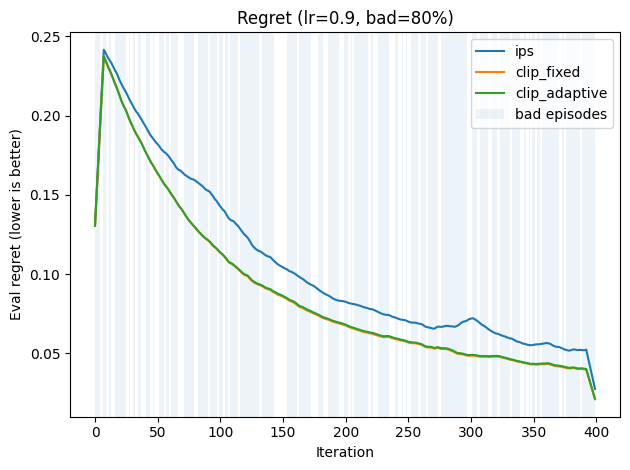

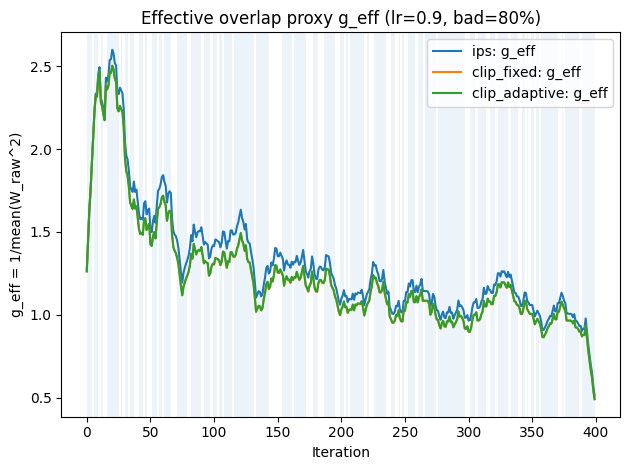

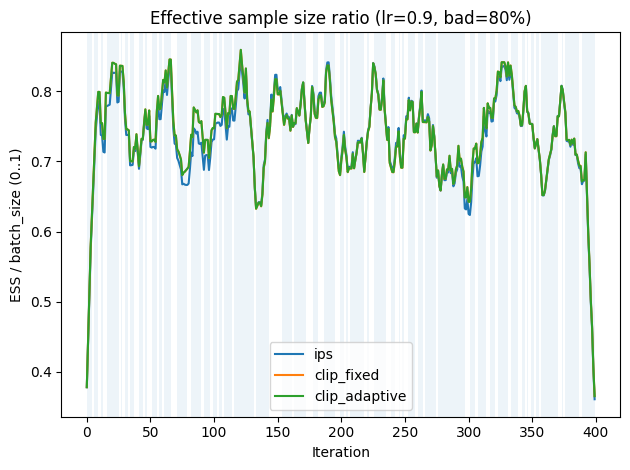

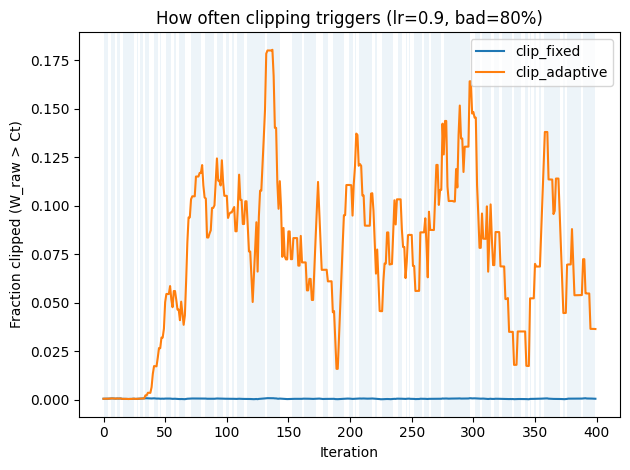

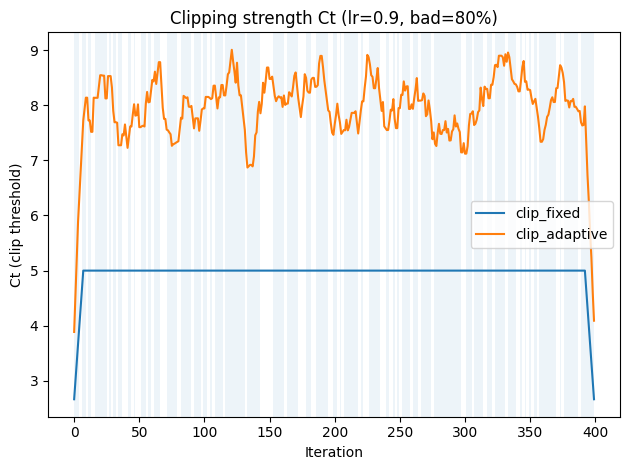

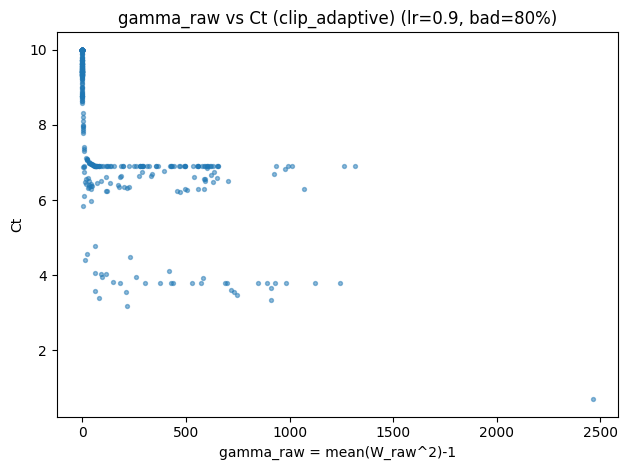

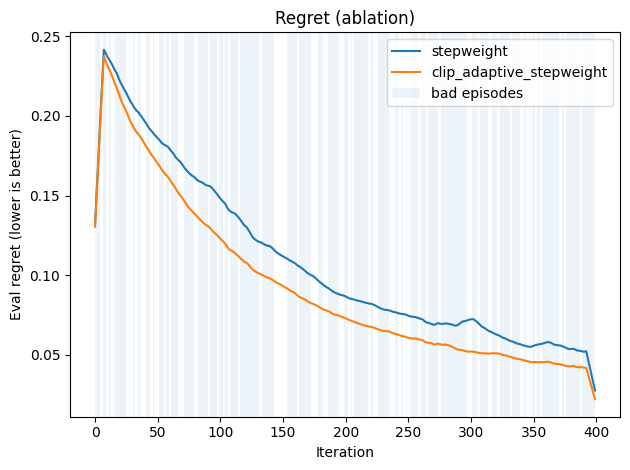

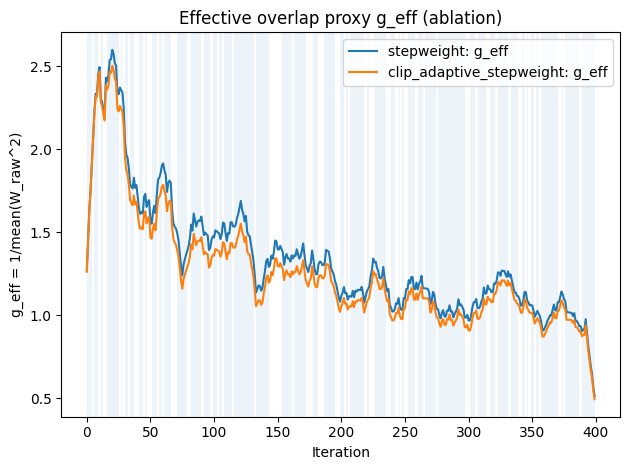

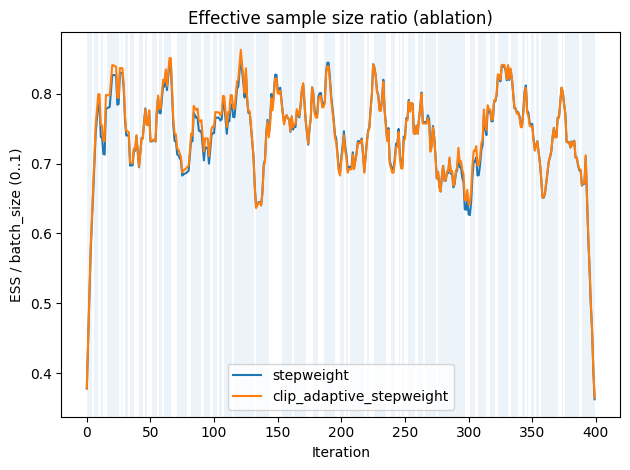

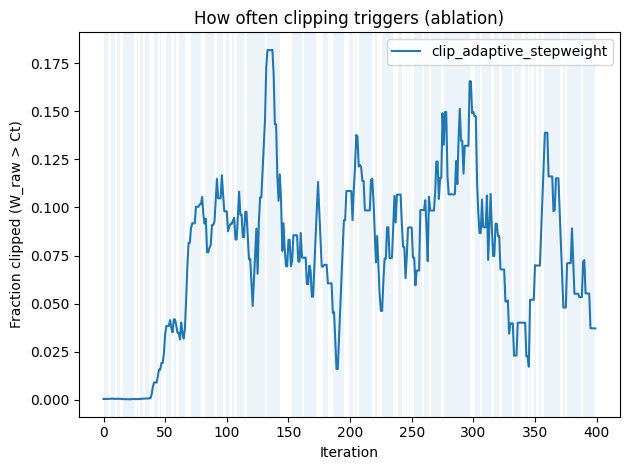

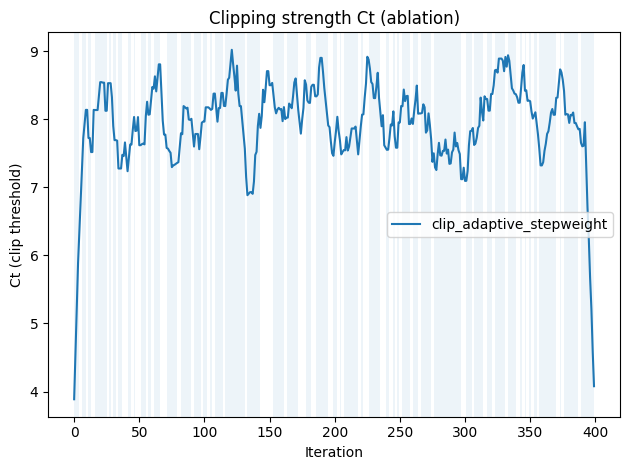

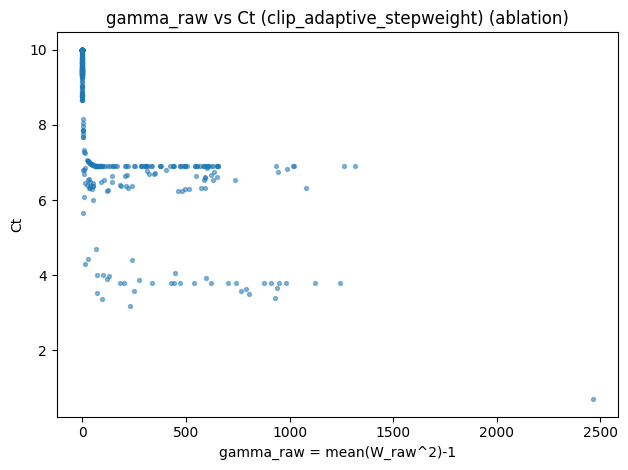

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Keep your existing: sigmoid, oracle_action, sample_reward_vec, scalarize_reward,
# ConditionedPolicy (unchanged)
# -------------------------

def sigmoid(x): return 1.0/(1.0+np.exp(-x))
def oracle_action(w): return 0 if w > 0.5 else 1

def sample_reward_vec(a, sigma_r, rng):
    mean = np.array([1.0, 0.0]) if a == 0 else np.array([0.0, 1.0])
    return mean + rng.normal(scale=sigma_r, size=2)

def scalarize_reward(w, r_vec):
    return w*r_vec[0] + (1.0-w)*r_vec[1]

class ConditionedPolicy:
    def __init__(self, theta=None):
        self.theta = np.zeros(2) if theta is None else np.array(theta, dtype=float)

    def p0(self, w):
        x = np.array([1.0, w-0.5])
        return sigmoid(self.theta @ x)

    def prob(self, a, w):
        p0 = self.p0(w)
        return p0 if a == 0 else (1.0-p0)

    def grad_log_prob(self, a, w):
        x = np.array([1.0, w-0.5])
        p0 = self.p0(w)
        return (1.0-p0)*x if a == 0 else (-p0)*x


# -------------------------
# Behavior: episode-level mode (IMPORTANT CHANGE)
# -------------------------
class TwoModeEnsembleBehaviorEpisode:
    """
    Each episode picks ONE mode k ~ Categorical(p_mode), then uses it for the whole batch.
    Mode k has (p_err, eps):
      - oracle routing flipped with prob p_err
      - epsilon exploration mixes with uniform
    """
    def __init__(self, modes, p_mode, rng=None):
        self.modes = list(modes)
        self.p_mode = np.array(p_mode, dtype=float)
        self.p_mode = self.p_mode / np.sum(self.p_mode)
        self.rng = np.random.default_rng() if rng is None else rng

    def sample_mode(self):
        return int(self.rng.choice(len(self.modes), p=self.p_mode))

    def mu_probs_given_mode(self, w, k):
        p_err = float(self.modes[k]["p_err"])
        eps   = float(self.modes[k]["eps"])
        a_star = oracle_action(w)
        p0_noeps = (1.0 - p_err) if a_star == 0 else p_err
        p1_noeps = 1.0 - p0_noeps
        p0 = (1.0 - eps) * p0_noeps + eps * 0.5
        p1 = (1.0 - eps) * p1_noeps + eps * 0.5
        return p0, p1

    def sample_action_given_mode(self, w, k):
        p0, p1 = self.mu_probs_given_mode(w, k)
        a = 0 if self.rng.random() < p0 else 1
        return a, (p0, p1)

# -------------------------
# Evaluation
# -------------------------
def evaluate_policy(policy, sigma_r, n_eval=20000, seed=0):
    rng = np.random.default_rng(seed)
    regrets = []
    for _ in range(n_eval):
        w = float(rng.random())
        a = 0 if rng.random() < policy.p0(w) else 1
        r = sample_reward_vec(a, sigma_r, rng)
        y = scalarize_reward(w, r)
        q_star = max(w, 1.0-w)
        regrets.append(q_star - y)
    return float(np.mean(regrets))

# -------------------------
# Training with method variable
# -------------------------
def run(method,
        seed=0,
        iters=400,
        batch_size=512,
        lr=0.9,
        sigma_r=0.1,
        modes=None,
        p_mode=None,
        C_fixed=5.0,
        C0=10.0,
        Gmax=200.0,
        # stepweight
        weight_pow=0.5,
        warmup=30,
        h_min=0.05,
        ema_beta=0.01):
    """
    method in:
      - "ips"
      - "stepweight"
      - "clip_fixed"
      - "clip_adaptive"
      - "clip_adaptive_stepweight"
    """
    assert method in {"ips","stepweight","clip_fixed","clip_adaptive","clip_adaptive_stepweight"}
    rng = np.random.default_rng(seed)

    if modes is None:
        modes = [
            {"p_err": 0.0, "eps": 0.001},  # bad overlap
            {"p_err": 0.5, "eps": 0.30},   # good overlap
        ]
    if p_mode is None:
        p_mode = [0.8, 0.2]

    behavior = TwoModeEnsembleBehaviorEpisode(modes=modes, p_mode=p_mode, rng=rng)
    policy = ConditionedPolicy(theta=[0.0, 0.0])

    gamma_prev = 0.0
    h_bar = 1.0

    logs = {k: [] for k in [
        "eval_regret",
        "mode_k", "mode_is_bad",
        "gamma_raw",
        "g_eff",            # 1/mean(W_raw^2)
        "ess_ratio",        # ESS/batch_size in [0,1]
        "Ct",
        "clip_frac",        # frac(W_raw > Ct)
        "p95_w2_raw",
    ]}

    for t in range(iters):
        # episode mode
        k = behavior.sample_mode()
        is_bad = 1.0 if k == 0 else 0.0

        # predictable stepweight (uses gamma_prev)
        use_step = method in {"stepweight","clip_adaptive_stepweight"}
        if use_step and t >= warmup:
            h_t = (1.0 + min(gamma_prev, Gmax)) ** (-weight_pow)
            h_bar = (1.0 - ema_beta) * h_bar + ema_beta * h_t
            h_eff = max(h_min, h_t / (h_bar + 1e-12))
        else:
            h_eff = 1.0

        # collect batch under this episode mode
        ws = rng.random(batch_size)
        actions = np.zeros(batch_size, dtype=int)
        mu_ps = np.zeros((batch_size,2), dtype=float)
        ys = np.zeros(batch_size, dtype=float)

        for i in range(batch_size):
            w = float(ws[i])
            a, (p0,p1) = behavior.sample_action_given_mode(w, k)
            actions[i] = a
            mu_ps[i,0] = p0
            mu_ps[i,1] = p1
            r = sample_reward_vec(a, sigma_r, rng)
            ys[i] = scalarize_reward(w, r)

        # raw W
        W_raw = np.zeros(batch_size, dtype=float)
        for i in range(batch_size):
            w = float(ws[i]); a = int(actions[i])
            mu_a = float(mu_ps[i,a])
            pi_a = float(policy.prob(a, w))
            W_raw[i] = pi_a / (mu_a + 1e-12)

        w2_raw = W_raw * W_raw
        mean_w2_raw = float(np.mean(w2_raw))
        gamma_raw = max(mean_w2_raw - 1.0, 0.0)

        # effective overlap proxy (your draft-style)
        g_eff = 1.0 / (mean_w2_raw + 1e-12)

        # ESS ratio in [0,1]
        ess = (np.sum(W_raw)**2) / (np.sum(w2_raw) + 1e-12)
        ess_ratio = float(ess / batch_size)

        # clipping
        if method == "clip_fixed":
            Ct = float(C_fixed)
        elif method in {"clip_adaptive","clip_adaptive_stepweight"}:
            Ct = float(C0 / np.sqrt(1.0 + min(gamma_raw, Gmax)))
        else:
            Ct = float("inf")

        if np.isfinite(Ct):
            W_used = np.minimum(W_raw, Ct)
            clip_frac = float(np.mean(W_raw > Ct))
        else:
            W_used = W_raw
            clip_frac = 0.0

        # gradient
        grad = np.zeros_like(policy.theta)
        for i in range(batch_size):
            w = float(ws[i]); a = int(actions[i])
            grad += ys[i] * W_used[i] * policy.grad_log_prob(a, w)
        grad /= float(batch_size)

        # update
        policy.theta += lr * h_eff * grad

        # next stepweight uses gamma_prev
        gamma_prev = gamma_raw

        # eval
        regret = evaluate_policy(policy, sigma_r, n_eval=6000, seed=seed + 999 + t)

        # log
        logs["eval_regret"].append(regret)
        logs["mode_k"].append(k)
        logs["mode_is_bad"].append(is_bad)
        logs["gamma_raw"].append(gamma_raw)
        logs["g_eff"].append(g_eff)
        logs["ess_ratio"].append(ess_ratio)
        logs["Ct"].append(np.nan if not np.isfinite(Ct) else Ct)
        logs["clip_frac"].append(clip_frac)
        logs["p95_w2_raw"].append(float(np.percentile(w2_raw, 95)))

    for k in logs:
        logs[k] = np.array(logs[k], dtype=float)
    return logs


# -------------------------
# Helpers: run many + intuitive plots
# -------------------------
def run_many(methods, seeds=(0,1,2), **kwargs):
    return {m: [run(m, seed=s, **kwargs) for s in seeds] for m in methods}

def mean_curve(outs_for_method, key):
    return np.mean([o[key] for o in outs_for_method], axis=0)

def smooth(x, w=15):
    if w <= 1: return x
    k = np.ones(w) / w
    return np.convolve(x, k, mode="same")

def plot_intuitive(outs, methods, smooth_w=15, title_suffix=""):
    # Use mode shading from first method/seed (all share same env schedule if same seed list)
    ref = outs[methods[0]][0]
    bad = ref["mode_is_bad"].astype(bool)
    T = len(bad)
    xs = np.arange(T)

    # 1) Regret (smoothed) + bad shading
    plt.figure()
    for m in methods:
        y = mean_curve(outs[m], "eval_regret")
        plt.plot(xs, smooth(y, smooth_w), label=m)
    ymin, ymax = plt.ylim()
    plt.fill_between(xs, ymin, ymax, where=bad, alpha=0.08, label="bad episodes")
    plt.ylim(ymin, ymax)
    plt.xlabel("Iteration")
    plt.ylabel("Eval regret (lower is better)")
    plt.title(f"Regret {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 2) g_eff and ESS ratio (both very intuitive, both in [0,1]-ish)
    plt.figure()
    for m in methods:
        y = mean_curve(outs[m], "g_eff")
        plt.plot(xs, smooth(y, smooth_w), label=f"{m}: g_eff")
    ymin, ymax = plt.ylim()
    plt.fill_between(xs, ymin, ymax, where=bad, alpha=0.08)
    plt.ylim(ymin, ymax)
    plt.xlabel("Iteration")
    plt.ylabel("g_eff = 1/mean(W_raw^2)")
    plt.title(f"Effective overlap proxy g_eff {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure()
    for m in methods:
        y = mean_curve(outs[m], "ess_ratio")
        plt.plot(xs, smooth(y, smooth_w), label=m)
    ymin, ymax = plt.ylim()
    plt.fill_between(xs, ymin, ymax, where=bad, alpha=0.08)
    plt.ylim(ymin, ymax)
    plt.xlabel("Iteration")
    plt.ylabel("ESS / batch_size (0..1)")
    plt.title(f"Effective sample size ratio {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 3) Clip fraction and Ct (only for clipped methods)
    plt.figure()
    any_plotted = False
    for m in methods:
        y = mean_curve(outs[m], "clip_frac")
        if np.allclose(y, 0.0): 
            continue
        any_plotted = True
        plt.plot(xs, smooth(y, smooth_w), label=m)
    if any_plotted:
        ymin, ymax = plt.ylim()
        plt.fill_between(xs, ymin, ymax, where=bad, alpha=0.08)
        plt.ylim(ymin, ymax)
        plt.xlabel("Iteration")
        plt.ylabel("Fraction clipped (W_raw > Ct)")
        plt.title(f"How often clipping triggers {title_suffix}".strip())
        plt.legend()
        plt.tight_layout()
        plt.show()

    plt.figure()
    for m in methods:
        Ct = mean_curve(outs[m], "Ct")
        if np.all(np.isnan(Ct)): 
            continue
        plt.plot(xs, smooth(Ct, smooth_w), label=m)
    ymin, ymax = plt.ylim()
    plt.fill_between(xs, ymin, ymax, where=bad, alpha=0.08)
    plt.ylim(ymin, ymax)
    plt.xlabel("Iteration")
    plt.ylabel("Ct (clip threshold)")
    plt.title(f"Clipping strength Ct {title_suffix}".strip())
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 4) Gamma vs Ct scatter (for adaptive clip only): shows the monotone relation directly
    for m in methods:
        if m not in {"clip_adaptive","clip_adaptive_stepweight"}:
            continue
        g = mean_curve(outs[m], "gamma_raw")
        Ct = mean_curve(outs[m], "Ct")
        plt.figure()
        plt.scatter(g, Ct, s=8, alpha=0.5)
        plt.xlabel("gamma_raw = mean(W_raw^2)-1")
        plt.ylabel("Ct")
        plt.title(f"gamma_raw vs Ct ({m}) {title_suffix}".strip())
        plt.tight_layout()
        plt.show()

methods_main = ["ips", "clip_fixed", "clip_adaptive"]  # 先主线
config = dict(
    iters=400,
    batch_size=512,
    lr=0.9,
    sigma_r=0.10,
    modes=[{"p_err":0.0,"eps":0.001},{"p_err":0.5,"eps":0.30}],
    p_mode=[0.8,0.2],
    C_fixed=5.0,
    C0=10.0,
    Gmax=200.0,
)
outs = run_many(methods_main, seeds=(0,1,2), **config)
plot_intuitive(outs, methods_main, smooth_w=15, title_suffix="(lr=0.9, bad=80%)")

methods_ablate = ["stepweight", "clip_adaptive_stepweight"]
outs2 = run_many(methods_ablate, seeds=(0,1,2), **config)
plot_intuitive(outs2, methods_ablate, smooth_w=15, title_suffix="(ablation)")
